# ЛР2. Анализ результатов экспериментов

Блокнот **только читает** результаты: обучение и оценивание выполняются скриптами
`python -m src.train --all` и `python -m src.evaluate`. Скрытой логики обучения здесь нет.
Перед запуском выполните эти две команды из корня проекта.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 200)

## 1. Сводная таблица E0–E4 (CV внутри train, тест — один раз)

In [2]:
res = pd.read_csv("reports/lab02-results.csv")
cols = ["id", "best_params", "cv_mse_mean", "cv_mse_std", "cv_mae_mean", "cv_r2_mean",
        "test_mse", "test_mae", "test_r2", "test_n_negative_predictions", "selected"]
res[cols].sort_values("cv_mse_mean").round(3)

,id,best_params,cv_mse_mean,cv_mse_std,cv_mae_mean,cv_r2_mean,test_mse,test_mae,test_r2,test_n_negative_predictions,selected
6,E2_ridge_loglog,"{""alpha"": 10.0}",3269.654,1358.003,35.230,0.970,2230.038,29.562,0.979,0,False
2,E1_esharma3,{},3288.153,2058.186,32.254,0.971,1429.289,23.754,0.986,0,True
5,E1_ols_loglog,{},3352.627,1705.387,32.862,0.969,1658.570,26.150,0.984,0,False
11,E4_ridge_loglog_vproxy,"{""alpha"": 0.3}",3362.813,1793.928,33.096,0.970,1729.777,26.068,0.983,0,False
12,E4_ridge_vproxy,"{""alpha"": 0.1}",6301.297,4478.202,48.135,0.944,2640.188,37.818,0.975,1,False
9,E4_ols_vproxy,{},6562.585,4213.293,50.574,0.941,2662.440,37.674,0.974,1,False
8,E3_random_forest,"{""max_depth"": 6, ""max_features"": 0.5, ""min_sam...",9035.589,12426.310,44.173,0.928,2443.382,34.925,0.976,0,False
10,E4_ols_vproxy_only,{},9194.276,7338.665,56.046,0.920,3164.196,36.703,0.970,0,False
7,E3_hist_gb,"{""learning_rate"": 0.05, ""max_depth"": null, ""mi...",9459.285,10354.996,48.889,0.925,3559.011,42.741,0.966,0,False
3,E1_ols,{},15051.749,10159.022,79.932,0.867,7531.988,73.976,0.928,3,False


Выбор итоговой модели сделан **только по CV** по правилу из `configs/base.yaml`.
Обратите внимание на std: разница между лучшими лог-моделями (E1_esharma3, E1_ols_loglog,
E2, E4_ridge_loglog_vproxy) меньше одного стандартного отклонения.

## 2. Мультиколлинеарность: VIF и корреляции

In [3]:
display(pd.read_csv("reports/tables/lab02-vif.csv", index_col=0))
pd.read_csv("reports/tables/lab02-correlations.csv", index_col=0)

,VIF_raw,VIF_raw_plus_Vproxy,VIF_log1p,VIF_log1p_plus_Vproxy
Height,14.4,20.4,17.5,135.1
Length1,1557.3,1576.9,1138.8,1595.0
Length2,2091.7,2091.7,1589.0,2077.4
Length3,417.6,434.3,436.4,507.9
V_proxy,NaN,9.6,NaN,812.6
Width,12.0,12.2,21.8,112.2


,Length1,Length2,Length3,Height,Width,V_proxy,Weight
Length1,1.0000,0.9995,0.9912,0.6188,0.8553,0.7777,0.8978
Length2,0.9995,1.0000,0.9936,0.6353,0.8619,0.7876,0.9012
Length3,0.9912,0.9936,1.0000,0.7000,0.8635,0.8184,0.9057
Height,0.6188,0.6353,0.7000,1.0000,0.7809,0.8905,0.7416
Width,0.8553,0.8619,0.8635,0.7809,1.0000,0.8809,0.8943
V_proxy,0.7777,0.7876,0.8184,0.8905,0.8809,1.0000,0.9296
Weight,0.8978,0.9012,0.9057,0.7416,0.8943,0.9296,1.0000


## 3. Устойчивость коэффициентов по 15 разбиениям CV

In [4]:
for run in ["e1_ols", "e1_ols_loglog", "e2_ridge_loglog", "e4_ols_vproxy", "e4_ridge_vproxy"]:
    c = pd.read_csv(f"runs/{run}/coefficients.csv", index_col=0)
    print(run); display(c[c.index.str.startswith("num__")].round(3))

e1_ols


,coef_final,coef_cv_mean,coef_cv_std,coef_cv_cv
num__Length1,-538.404,-499.617,339.258,0.679
num__Length2,824.071,825.380,241.126,0.292
num__Length3,59.845,4.222,350.228,82.950
num__Height,60.592,69.675,78.366,1.125
num__Width,16.026,22.243,37.600,1.690


e1_ols_loglog


,coef_final,coef_cv_mean,coef_cv_std,coef_cv_cv
num__Length1,0.187,0.209,0.215,1.030
num__Length2,-0.395,-0.401,0.252,0.627
num__Length3,0.917,0.889,0.243,0.273
num__Height,0.314,0.321,0.078,0.242
num__Width,0.308,0.308,0.041,0.131


e2_ridge_loglog


,coef_final,coef_cv_mean,coef_cv_std,coef_cv_cv
num__Length1,0.227,0.228,0.012,0.055
num__Length2,0.236,0.236,0.013,0.054
num__Length3,0.239,0.239,0.012,0.050
num__Height,0.299,0.292,0.013,0.043
num__Width,0.312,0.306,0.012,0.039


e4_ols_vproxy


,coef_final,coef_cv_mean,coef_cv_std,coef_cv_cv
num__Length1,282.861,285.641,212.046,0.742
num__Length2,-457.822,-448.983,314.244,0.700
num__Length3,460.200,435.976,253.979,0.583
num__Height,-260.366,-244.393,73.759,0.302
num__Width,-19.802,-14.606,28.474,1.949
num__V_proxy,316.161,310.128,26.850,0.087


e4_ridge_vproxy


,coef_final,coef_cv_mean,coef_cv_std,coef_cv_cv
num__Length1,87.171,86.893,28.257,0.325
num__Length2,17.121,28.929,34.560,1.195
num__Length3,157.211,132.945,69.277,0.521
num__Height,-203.557,-182.107,53.496,0.294
num__Width,-18.826,-13.902,30.005,2.158
num__V_proxy,292.624,283.373,25.889,0.091


## 4. Остатки

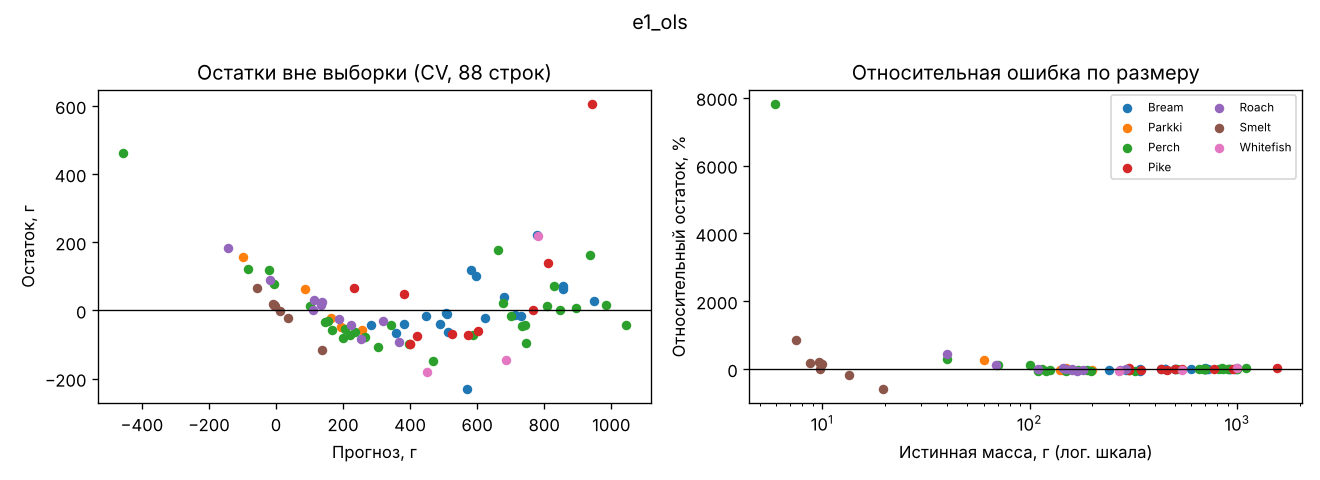

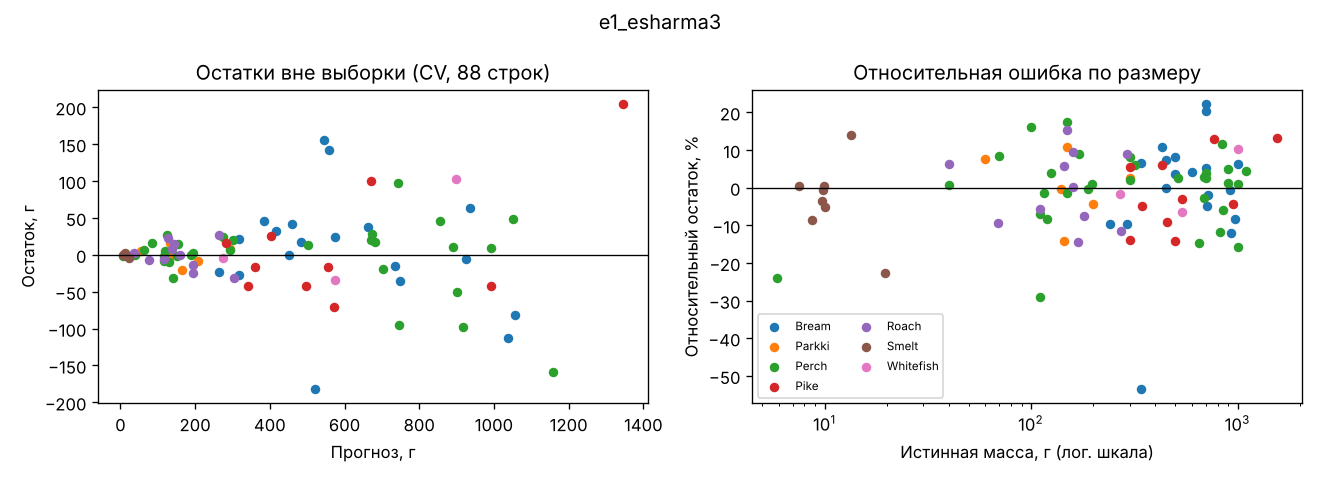

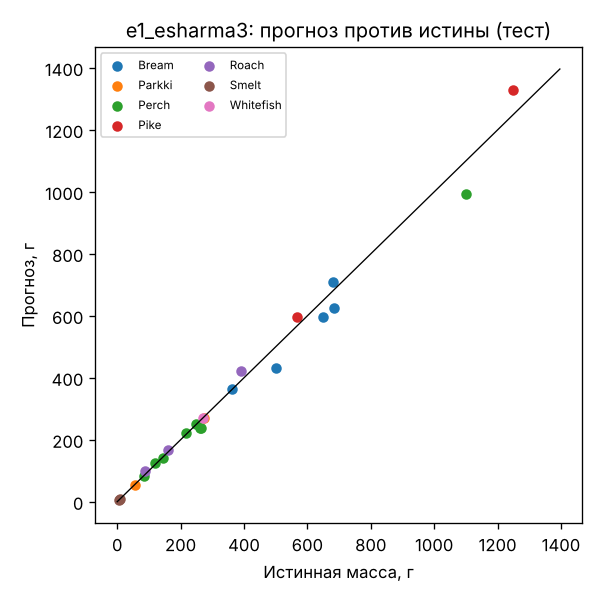

In [5]:
for f in ["lab02-e1_ols-residuals-oof.png", "lab02-e1_esharma3-residuals-oof.png",
          "lab02-e1_esharma3-pred-vs-true.png"]:
    display(Image(f"reports/figures/{f}"))

## 5. Анализ ошибок итоговой модели

In [6]:
run = res.loc[res["selected"], "run_name"].item()
for key in ["zones_oof", "top_errors_oof", "top_errors_test", "mae_by_species_oof",
            "mae_by_weight_oof", "mae_by_weight_test"]:
    print(key); display(pd.read_csv(f"reports/tables/lab02-{run}-{key}.csv"))

zones_oof


,prediction_bin,size,mean,std
0,"(7.311999999999999, 118.703]",18,0.07,5.38
1,"(118.703, 206.203]",17,0.45,16.46
2,"(206.203, 452.284]",18,4.05,24.87
3,"(452.284, 722.488]",17,13.60,78.57
4,"(722.488, 1345.473]",18,-6.31,90.30


top_errors_oof


,row,Species,Weight,Length1,Length2,Length3,Height,Width,prediction,residual,abs_error
0,13,Pike,1550.0,56.0,60.0,64.0,9.60,6.14,1345.47,204.53,204.53
1,68,Bream,340.0,29.5,32.0,37.3,13.91,5.07,521.95,-181.95,181.95
2,41,Perch,1000.0,40.2,43.5,46.0,12.60,8.14,1158.54,-158.54,158.54
3,4,Bream,700.0,30.4,33.0,38.3,14.86,5.29,544.20,155.80,155.80
4,6,Bream,700.0,30.4,33.0,38.5,14.94,5.20,557.54,142.46,142.46


top_errors_test


...

,Species,n,mae,mean_residual,mean_weight,relative_mae_%
0,Bream,19,56.16,5.26,605.05,9.28
1,Parkki,6,9.74,-0.28,165.83,5.87
2,Perch,31,28.54,-2.23,449.03,6.36
3,Pike,10,57.70,11.67,614.10,9.40
4,Roach,11,14.28,-0.57,158.64,9.00
5,Smelt,8,1.01,-0.52,11.09,9.13
6,Whitefish,3,47.22,21.30,603.33,7.83


mae_by_weight_oof


,Weight,n,mae,mean_residual,mean_weight,relative_mae_%
0,<100 г,14,2.09,0.08,26.69,7.82
1,100–300 г,27,13.63,-2.28,170.67,7.99
2,300–700 г,24,34.82,-8.46,449.17,7.75
3,≥700 г,23,72.23,20.12,888.43,8.13


mae_by_weight_test


,Weight,n,mae,mean_residual,mean_weight,relative_mae_%
0,<100 г,5,3.03,-1.29,48.70,6.22
1,100–300 г,9,8.15,4.86,218.00,3.74
2,300–700 г,7,38.75,12.50,547.86,7.07
3,≥700 г,2,93.29,13.36,1175.00,7.94


## 6. Отрицательные прогнозы

In [7]:
neg = pd.read_csv("reports/tables/lab02-negative-predictions.csv")
neg[neg["n_negative"] > 0]

,run,part,n,n_negative,min_prediction,n_nonfinite
6,e1_ols,oof,88,12,-455.47,0
7,e1_ols,test,23,3,-92.70,0
18,e4_ols_vproxy,oof,88,5,-119.24,0
19,e4_ols_vproxy,test,23,1,-15.31,0
24,e4_ridge_vproxy,oof,88,4,-134.42,0
25,e4_ridge_vproxy,test,23,1,-17.21,0
